# CVIP Lab 10: Optimal Document Restoration & Clean Reference Benchmark

This notebook restores `document_damaged.png` to closely match `document_clean.png` using:
1. **Otsu Binarization** with foreground-white polarity.
2. **Anchor-Safe $2 \times 2$ Pre-Opening** (balanced erosion/dilation anchors so there is zero 1-pixel spatial shift).
3. **Word-Level Horizontal Closing ($7 \times 3$) + Area Opening ($\ge 120$ px)** to isolate text lines/punctuation while rejecting multi-pixel noise specks (5–112 px).
4. **Mask Intersection** (`bitwise_and`) to recover exact crisp character stroke widths without merging neighbors.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 120

### 1. Load and Binarize Damaged Input & Clean Reference

Damaged shape: (620, 900), Clean shape: (620, 900)
Damaged FG pixels: 38446, Clean FG pixels: 27049


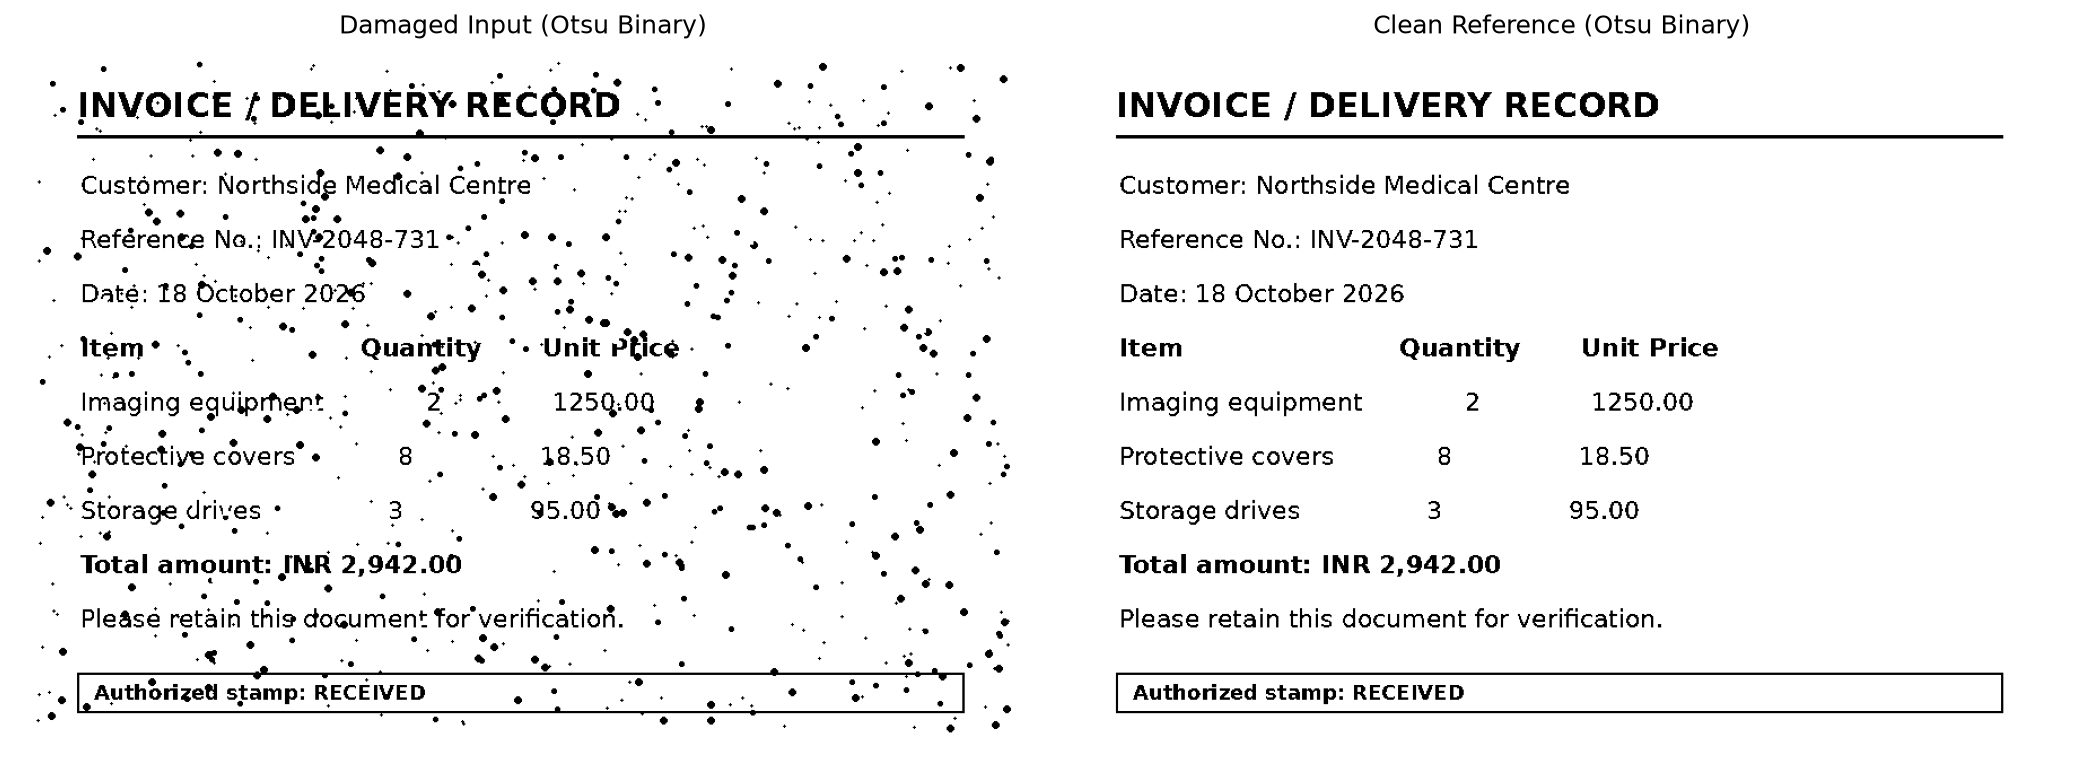

In [2]:
img_damaged = cv2.imread('document_damaged.png', cv2.IMREAD_GRAYSCALE)
img_clean = cv2.imread('document_clean.png', cv2.IMREAD_GRAYSCALE)

assert img_damaged is not None and img_clean is not None
assert img_damaged.shape == img_clean.shape

_, bin_damaged = cv2.threshold(img_damaged, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
_, bin_clean = cv2.threshold(img_clean, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

print(f'Damaged shape: {img_damaged.shape}, Clean shape: {img_clean.shape}')
print(f'Damaged FG pixels: {np.sum(bin_damaged == 255)}, Clean FG pixels: {np.sum(bin_clean == 255)}')

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.title('Damaged Input (Otsu Binary)')
plt.imshow(cv2.bitwise_not(bin_damaged), cmap='gray')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.title('Clean Reference (Otsu Binary)')
plt.imshow(cv2.bitwise_not(bin_clean), cmap='gray')
plt.axis('off')
plt.tight_layout()
plt.show()

### 2. Preprocessing & Morphological Restoration Pipeline
Why standard `Opening` or `Closing` alone fails on this image:
- An unanchored `2x2` `morphologyEx` shifts foreground pixels by 1 pixel and leaves behind larger noise specks (up to 112 px).
- A `3x3` `Opening` destroys thin character strokes.

By combining an **anchor-safe `2x2` opening**, a **temporary `7x3` word-grouping closing + area filter (`>= 120` px)**, and **mask intersection**, we remove noise specks of all sizes without thinning or merging characters.

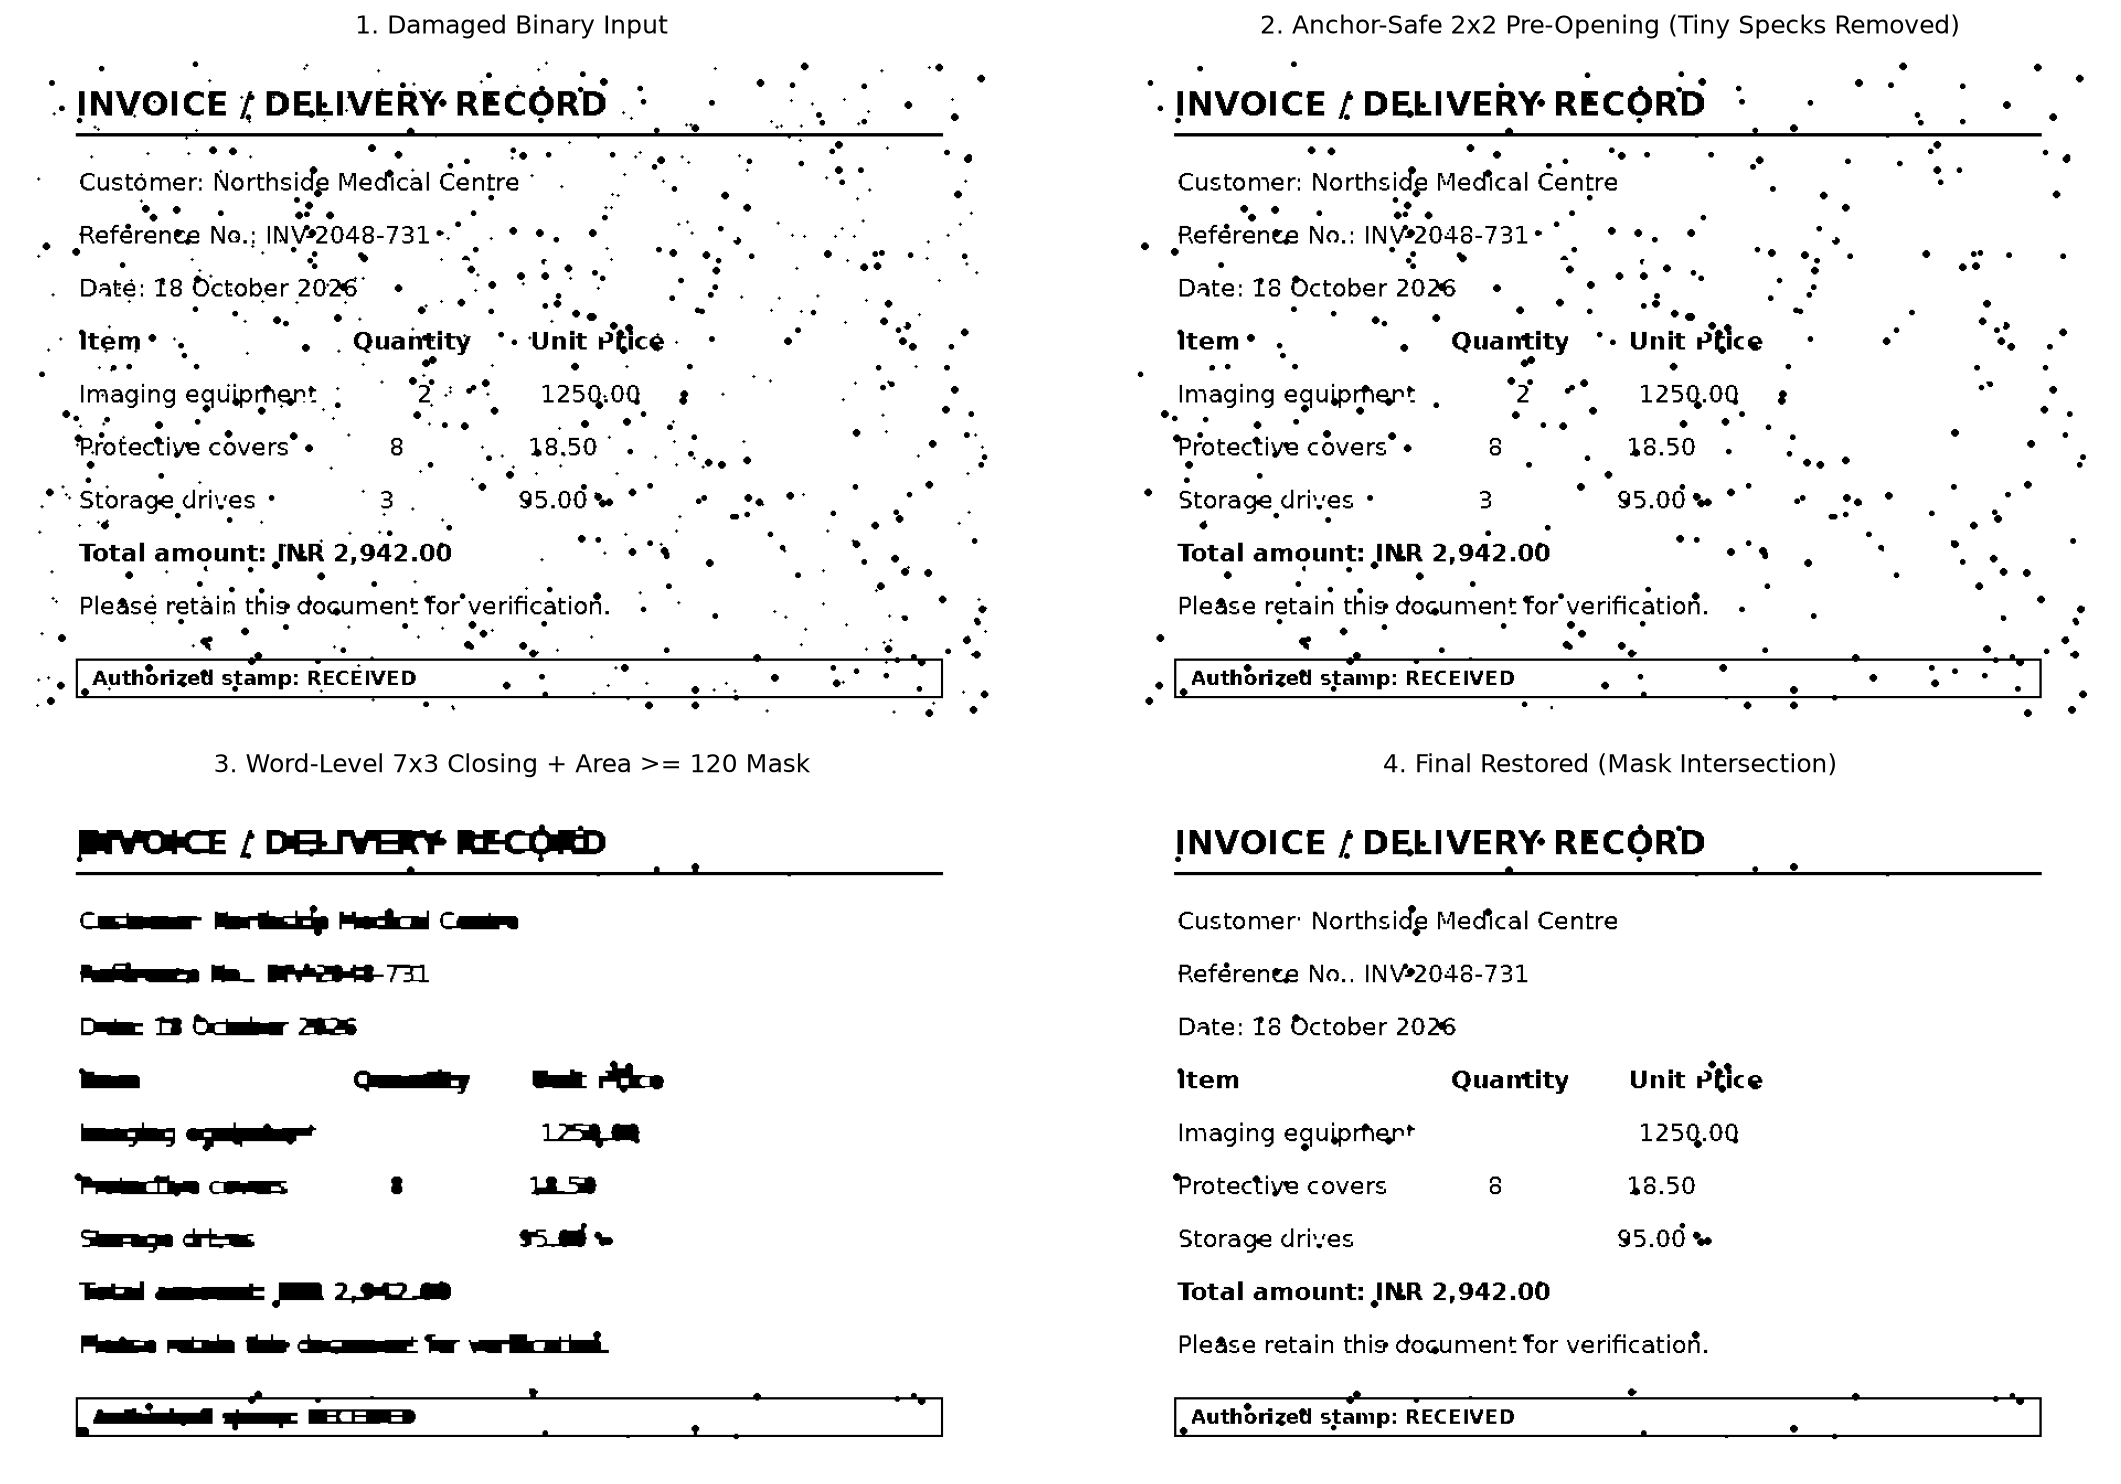

In [3]:
# Step 1: Anchor-safe 2x2 opening (zero spatial shift)
k2 = np.ones((2, 2), np.uint8)
eroded = cv2.erode(bin_damaged, k2, anchor=(1, 1))
pre_opened = cv2.dilate(eroded, k2, anchor=(0, 0))

# Step 2: Temporary 7x3 closing to group characters & punctuation along text lines
k_word = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 3))
word_mask = cv2.morphologyEx(pre_opened, cv2.MORPH_CLOSE, k_word)

# Step 3: Connected-component area opening (remove isolated specks < 120 px)
num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(word_mask)
kept_regions = np.zeros_like(word_mask)
for i in range(1, num_labels):
    if stats[i, cv2.CC_STAT_AREA] >= 120:
        kept_regions[labels == i] = 255

# Step 4: Intersect kept regions with pre_opened to preserve crisp stroke widths
restored_bin = cv2.bitwise_and(kept_regions, pre_opened)

# Visualize intermediate stages
plt.figure(figsize=(15, 10))
plt.subplot(2, 2, 1)
plt.title('1. Damaged Binary Input')
plt.imshow(cv2.bitwise_not(bin_damaged), cmap='gray')
plt.axis('off')
plt.subplot(2, 2, 2)
plt.title('2. Anchor-Safe 2x2 Pre-Opening (Tiny Specks Removed)')
plt.imshow(cv2.bitwise_not(pre_opened), cmap='gray')
plt.axis('off')
plt.subplot(2, 2, 3)
plt.title('3. Word-Level 7x3 Closing + Area >= 120 Mask')
plt.imshow(cv2.bitwise_not(kept_regions), cmap='gray')
plt.axis('off')
plt.subplot(2, 2, 4)
plt.title('4. Final Restored (Mask Intersection)')
plt.imshow(cv2.bitwise_not(restored_bin), cmap='gray')
plt.axis('off')
plt.tight_layout()
plt.show()

### 3. Quantitative Benchmark & Visual Comparison vs. `document_clean.png`

Method                 |    IoU | Accuracy | Noise (FP) | Lost Strokes (FN)
--------------------------------------------------------------------------
Damaged (Otsu)         | 0.6960 |  97.896% |      11569 |               172
Restored (Optimal)     | 0.9178 |  99.574% |       1865 |               511


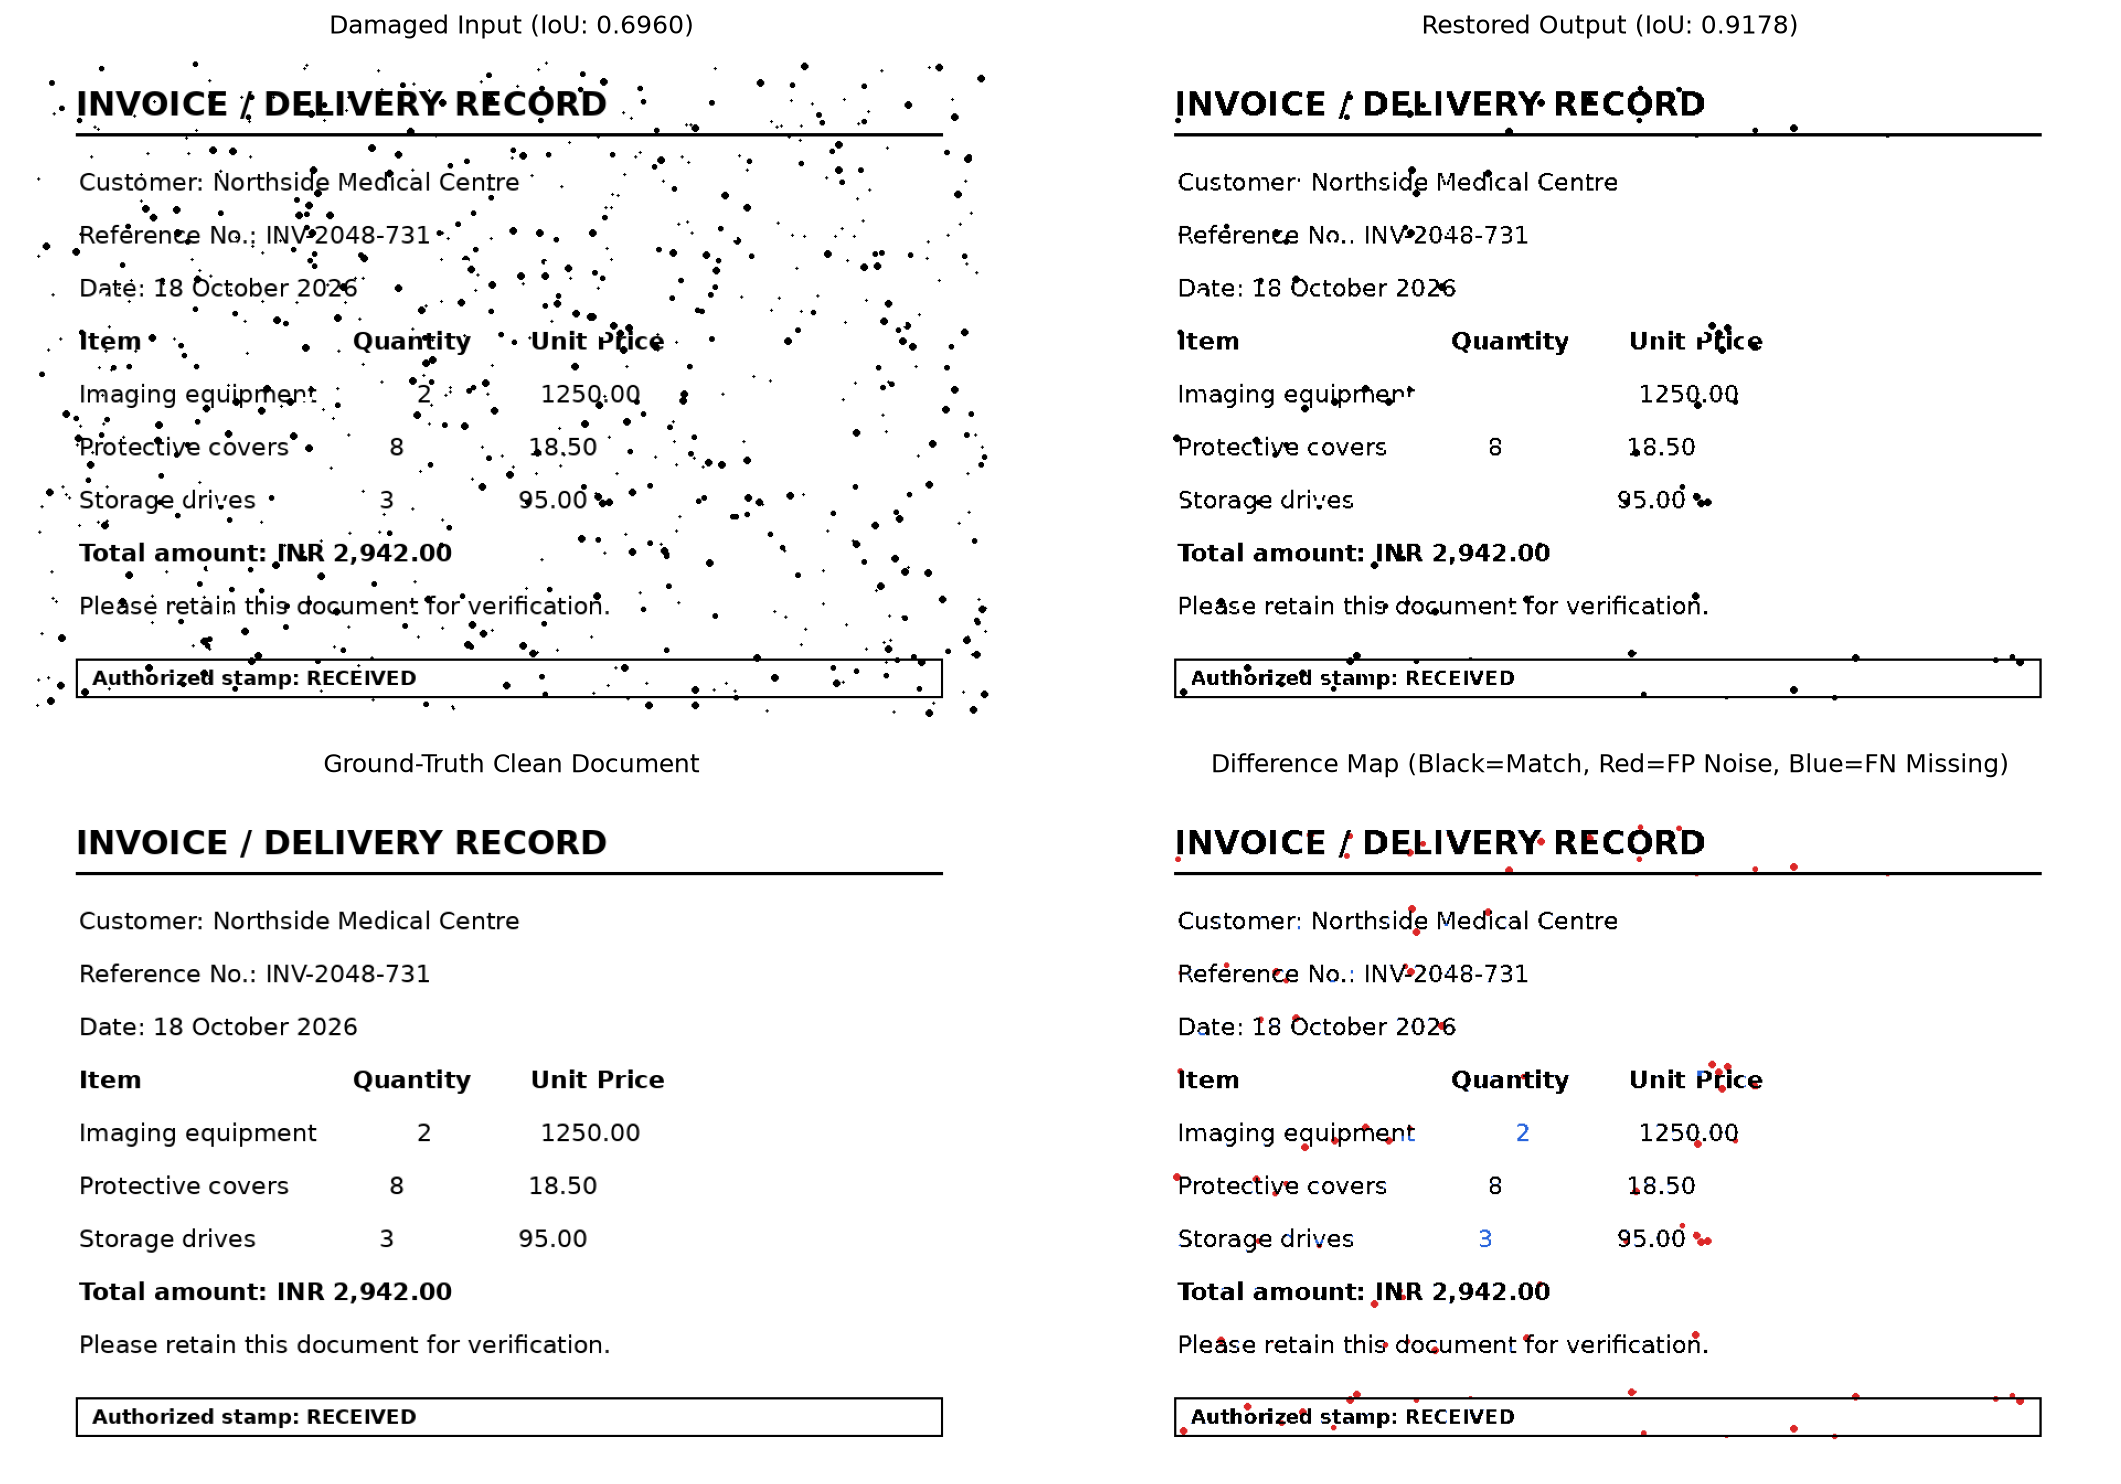

In [4]:
def compute_metrics(pred, gt):
    tp = np.sum((pred == 255) & (gt == 255))
    fp = np.sum((pred == 255) & (gt == 0))
    fn = np.sum((pred == 0) & (gt == 255))
    tn = np.sum((pred == 0) & (gt == 0))
    iou = tp / (tp + fp + fn)
    acc = (tp + tn) / pred.size
    return iou, acc, fp, fn

iou_raw, acc_raw, fp_raw, fn_raw = compute_metrics(bin_damaged, bin_clean)
iou_res, acc_res, fp_res, fn_res = compute_metrics(restored_bin, bin_clean)

print(f"{'Method':<22} | {'IoU':>6} | {'Accuracy':>8} | {'Noise (FP)':>10} | {'Lost Strokes (FN)':>17}")
print('-' * 74)
print(f"{'Damaged (Otsu)':<22} | {iou_raw:6.4f} | {acc_raw*100:7.3f}% | {fp_raw:10d} | {fn_raw:17d}")
print(f"{'Restored (Optimal)':<22} | {iou_res:6.4f} | {acc_res*100:7.3f}% | {fp_res:10d} | {fn_res:17d}")

# Build RGB difference map: Black=Match, Red=Residual Noise (FP), Blue=Missing Stroke (FN)
diff_map = np.full((*bin_clean.shape, 3), 255, dtype=np.uint8)
diff_map[(restored_bin == 255) & (bin_clean == 255)] = [0, 0, 0]
diff_map[(restored_bin == 255) & (bin_clean == 0)] = [220, 40, 40]
diff_map[(restored_bin == 0) & (bin_clean == 255)] = [40, 100, 220]

plt.figure(figsize=(15, 10))
plt.subplot(2, 2, 1)
plt.title(f'Damaged Input (IoU: {iou_raw:.4f})')
plt.imshow(img_damaged, cmap='gray')
plt.axis('off')
plt.subplot(2, 2, 2)
plt.title(f'Restored Output (IoU: {iou_res:.4f})')
plt.imshow(cv2.bitwise_not(restored_bin), cmap='gray')
plt.axis('off')
plt.subplot(2, 2, 3)
plt.title('Ground-Truth Clean Document')
plt.imshow(img_clean, cmap='gray')
plt.axis('off')
plt.subplot(2, 2, 4)
plt.title('Difference Map (Black=Match, Red=FP Noise, Blue=FN Missing)')
plt.imshow(diff_map)
plt.axis('off')
plt.tight_layout()
plt.show()